# Data Visualization: Faktor yang Berkaitan dengan Kelulusan Mahasiswa
**Mata Kuliah:** Data Mining (Pertemuan 6)  
**Nama:** Dio Raditya Putra Pratama | **NIM:** 2318044  
**Kampus:** Institut Teknologi Nasional Malang

## Tujuan
Mengeksplorasi dataset kelulusan mahasiswa secara visual untuk menemukan pola, distribusi, hubungan antarvariabel, dan tren yang berkaitan dengan **status kelulusan** (Tepat Waktu / Terlambat). Library yang digunakan adalah **Matplotlib** dan **Seaborn**.

## Dataset
`dataset_kelulusan_mahasiswa.csv` berisi 500 mahasiswa dari 5 jurusan (Informatika, Sistem Informasi, Teknik Elektro, Teknik Sipil, Teknik Industri) dengan 13 kolom: data akademik (semester, IPK, nilai UTS/UAS, tugas, kehadiran), kebiasaan belajar, aktivitas di luar kuliah (organisasi, kerja paruh waktu), dan status kelulusan sebagai target.

## Teknik visualisasi yang digunakan
Histogram, Boxplot, Scatter Plot, Line Chart, Bar Chart, dan Heatmap.

## 1. Import Library

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
WARNA = {"Tepat Waktu": "#1A7F8E", "Terlambat": "#F2A541"}   # warna konsisten untuk status kelulusan
os.makedirs("hasil_visualisasi", exist_ok=True)

## 2. Load Dataset
Upload `dataset_kelulusan_mahasiswa.csv` ke Colab lewat ikon folder di sidebar kiri. Jika memakai Google Drive, ganti path menjadi `/content/drive/MyDrive/Colab Notebooks/dataset_kelulusan_mahasiswa.csv` setelah `drive.mount`.

In [2]:
df = pd.read_csv("dataset_kelulusan_mahasiswa.csv")
print("Ukuran dataset: %d baris dan %d kolom\n" % df.shape)
df.head()

Ukuran dataset: 500 baris dan 13 kolom



,id_mahasiswa,jenis_kelamin,jurusan,semester,ipk,kehadiran_persen,jam_belajar_per_minggu,tugas_terkumpul,nilai_uts,nilai_uas,aktif_organisasi,kerja_paruh_waktu,status_kelulusan
0,MHS0001,Perempuan,Teknik Industri,8,2.22,50.2,6.9,5,57,64,Tidak,Tidak,Terlambat
1,MHS0002,Laki-laki,Teknik Sipil,2,3.06,65.5,12.6,9,69,71,Tidak,Tidak,Tepat Waktu
2,MHS0003,Perempuan,Teknik Sipil,4,2.68,60.3,9.1,8,54,63,Ya,Tidak,Terlambat
3,MHS0004,Perempuan,Teknik Elektro,5,2.48,55.0,9.4,8,33,58,Ya,Ya,Terlambat
4,MHS0005,Laki-laki,Teknik Elektro,7,2.69,67.7,15.0,8,50,53,Ya,Tidak,Terlambat


## 3. Persiapan Data
Data dibersihkan dengan langkah yang sama seperti pada tugas Data Cleansing agar hasil visualisasi tidak terpengaruh nilai kosong atau nilai ekstrem:
- **Missing value** pada `ipk`, `kehadiran_persen`, dan `jam_belajar_per_minggu` diisi median per jurusan.
- **Outlier** dibatasi (capping) dengan metode IQR, dengan batas logis (misalnya kehadiran dan nilai maksimal 100).
- Ditambahkan kolom `tepat_waktu` (1 = Tepat Waktu, 0 = Terlambat) untuk menghitung persentase dan korelasi.

In [3]:
print("Missing value sebelum:", df.isnull().sum().sum())

for kolom in ["ipk", "kehadiran_persen", "jam_belajar_per_minggu"]:
    df[kolom] = df[kolom].fillna(df.groupby("jurusan")[kolom].transform("median"))

batas_logis = {"ipk": (0, 4), "kehadiran_persen": (0, 100), "jam_belajar_per_minggu": (0, 168),
               "nilai_uts": (0, 100), "nilai_uas": (0, 100)}
for kolom, (lo, hi) in batas_logis.items():
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    df[kolom] = df[kolom].clip(max(q1 - 1.5 * iqr, lo), min(q3 + 1.5 * iqr, hi))

df["tepat_waktu"] = (df["status_kelulusan"] == "Tepat Waktu").astype(int)

print("Missing value sesudah:", df.isnull().sum().sum())
print("\nProporsi status kelulusan:")
print(df["status_kelulusan"].value_counts())
df.describe().T.round(2)

Missing value sebelum: 37
Missing value sesudah: 0

Proporsi status kelulusan:
status_kelulusan
Tepat Waktu    359
Terlambat      141
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
semester,500.0,4.95,1.96,2.00,3.00,5.00,7.00,8.00
ipk,500.0,3.06,0.32,2.21,2.85,3.08,3.28,3.92
kehadiran_persen,500.0,80.84,11.87,49.82,73.30,81.95,88.95,100.00
jam_belajar_per_minggu,500.0,11.67,4.66,1.00,8.50,12.10,14.80,24.25
tugas_terkumpul,500.0,11.22,2.14,5.00,10.00,12.00,13.00,14.00
nilai_uts,500.0,70.78,12.55,39.00,63.00,71.00,79.00,100.00
nilai_uas,500.0,71.41,12.68,37.50,63.00,71.00,80.00,100.00
tepat_waktu,500.0,0.72,0.45,0.00,0.00,1.00,1.00,1.00


Dataset berisi 359 mahasiswa Tepat Waktu (71,8%) dan 141 Terlambat (28,2%), sehingga kelas target tidak seimbang namun masih cukup untuk dianalisis.

## 4. Histogram: Distribusi IPK

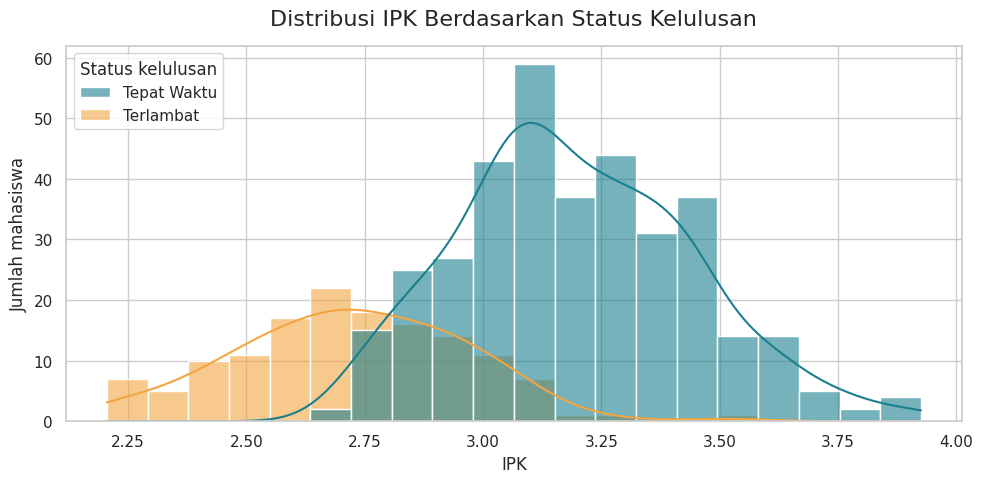

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="ipk", hue="status_kelulusan", bins=20, kde=True,
             palette=WARNA, hue_order=["Tepat Waktu", "Terlambat"], alpha=0.6)
plt.title("Distribusi IPK Berdasarkan Status Kelulusan", fontsize=16, pad=15)
plt.xlabel("IPK", fontsize=12)
plt.ylabel("Jumlah mahasiswa", fontsize=12)
sns.move_legend(plt.gca(), "upper left", title="Status kelulusan")
plt.tight_layout()
plt.savefig("hasil_visualisasi/01_histogram_ipk.png", dpi=150)
plt.show()

**Interpretasi:** IPK mahasiswa tersebar mulai sekitar 2,2 sampai 3,9 dengan rata-rata 3,06. Distribusi mahasiswa Tepat Waktu bergeser ke kanan (median 3,17), sedangkan mahasiswa Terlambat terkonsentrasi di IPK yang lebih rendah (median 2,72). Artinya IPK menjadi pembeda yang jelas antara kedua kelompok.

## 5. Boxplot: Kehadiran dan Jam Belajar

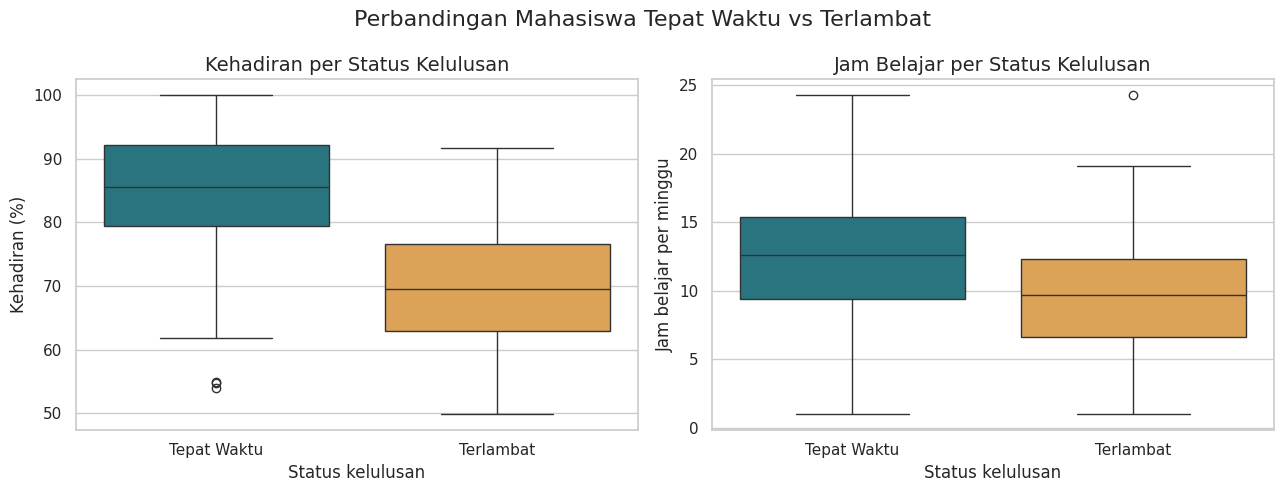

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x="status_kelulusan", y="kehadiran_persen", hue="status_kelulusan",
            order=["Tepat Waktu", "Terlambat"], palette=WARNA, legend=False, ax=axes[0])
axes[0].set_title("Kehadiran per Status Kelulusan", fontsize=14)
axes[0].set_xlabel("Status kelulusan")
axes[0].set_ylabel("Kehadiran (%)")

sns.boxplot(data=df, x="status_kelulusan", y="jam_belajar_per_minggu", hue="status_kelulusan",
            order=["Tepat Waktu", "Terlambat"], palette=WARNA, legend=False, ax=axes[1])
axes[1].set_title("Jam Belajar per Status Kelulusan", fontsize=14)
axes[1].set_xlabel("Status kelulusan")
axes[1].set_ylabel("Jam belajar per minggu")

plt.suptitle("Perbandingan Mahasiswa Tepat Waktu vs Terlambat", fontsize=16)
plt.tight_layout()
plt.savefig("hasil_visualisasi/02_boxplot_kehadiran_jam_belajar.png", dpi=150)
plt.show()

**Interpretasi:** Mahasiswa Tepat Waktu memiliki median kehadiran sekitar 85,6% dibanding 69,6% pada mahasiswa Terlambat, dan median jam belajar sekitar 12,6 jam dibanding 9,7 jam per minggu. Kedua kelompok masih tumpang tindih, jadi kehadiran dan jam belajar membantu membedakan tetapi tidak sepenuhnya memisahkan.

## 6. Scatter Plot: Kehadiran vs IPK

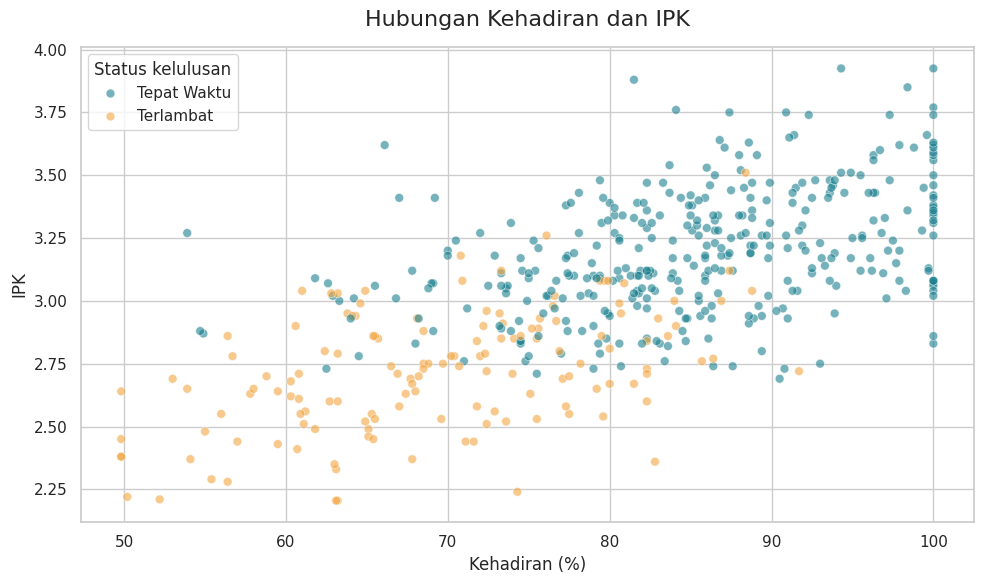

Korelasi kehadiran dan IPK: 0.66


In [6]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="kehadiran_persen", y="ipk", hue="status_kelulusan",
                palette=WARNA, hue_order=["Tepat Waktu", "Terlambat"], alpha=0.6, s=40)
plt.title("Hubungan Kehadiran dan IPK", fontsize=16, pad=15)
plt.xlabel("Kehadiran (%)", fontsize=12)
plt.ylabel("IPK", fontsize=12)
plt.legend(title="Status kelulusan")
plt.tight_layout()
plt.savefig("hasil_visualisasi/03_scatter_kehadiran_ipk.png", dpi=150)
plt.show()

print("Korelasi kehadiran dan IPK: %.2f" % df["kehadiran_persen"].corr(df["ipk"]))

**Interpretasi:** Titik membentuk pola naik dengan korelasi kehadiran dan IPK sebesar 0,66, artinya hubungan positif yang cukup kuat. Area kanan atas (kehadiran dan IPK tinggi) didominasi mahasiswa Tepat Waktu, sedangkan mahasiswa Terlambat menumpuk di area kiri bawah.

## 7. Line Chart: Tren per Semester

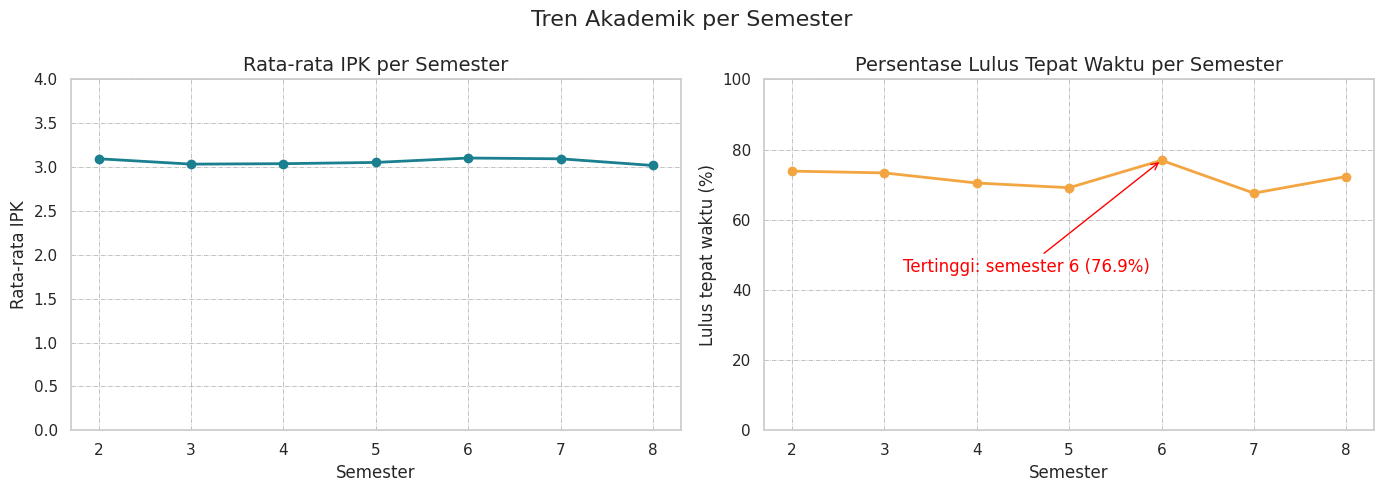

In [7]:
per_semester = df.groupby("semester").agg(rata_ipk=("ipk", "mean"),
                                          persen_tepat=("tepat_waktu", "mean")).reset_index()
per_semester["persen_tepat"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(per_semester["semester"], per_semester["rata_ipk"], color="#1A7F8E",
             marker="o", linestyle="-", linewidth=2)
axes[0].set_title("Rata-rata IPK per Semester", fontsize=14)
axes[0].set_xlabel("Semester")
axes[0].set_ylabel("Rata-rata IPK")
axes[0].set_ylim(0, 4)

axes[1].plot(per_semester["semester"], per_semester["persen_tepat"], color="#F2A541",
             marker="o", linestyle="-", linewidth=2)
axes[1].set_title("Persentase Lulus Tepat Waktu per Semester", fontsize=14)
axes[1].set_xlabel("Semester")
axes[1].set_ylabel("Lulus tepat waktu (%)")
axes[1].set_ylim(0, 100)
tertinggi = per_semester.loc[per_semester["persen_tepat"].idxmax()]
axes[1].annotate("Tertinggi: semester %d (%.1f%%)" % (tertinggi["semester"], tertinggi["persen_tepat"]),
                 xy=(tertinggi["semester"], tertinggi["persen_tepat"]),
                 xytext=(3.2, 45), color="red",
                 arrowprops=dict(arrowstyle="->", color="red"))

for ax in axes:
    ax.set_xticks(per_semester["semester"])
    ax.grid(color="darkgray", linestyle="-.", linewidth=0.5)

plt.suptitle("Tren Akademik per Semester", fontsize=16)
plt.tight_layout()
plt.savefig("hasil_visualisasi/04_line_tren_per_semester.png", dpi=150)
plt.show()

**Interpretasi:** Rata-rata IPK stabil di kisaran 3,0 sampai 3,1 pada semua semester, dan persentase lulus tepat waktu bergerak di kisaran 68% sampai 77% tanpa tren naik atau turun yang jelas. Semester 6 tertinggi dan semester 7 terendah, tetapi selisihnya kecil, jadi semester bukan faktor yang membedakan kelulusan (korelasi semester dengan status kelulusan mendekati 0).

## 8. Bar Chart: Lulus Tepat Waktu per Jurusan

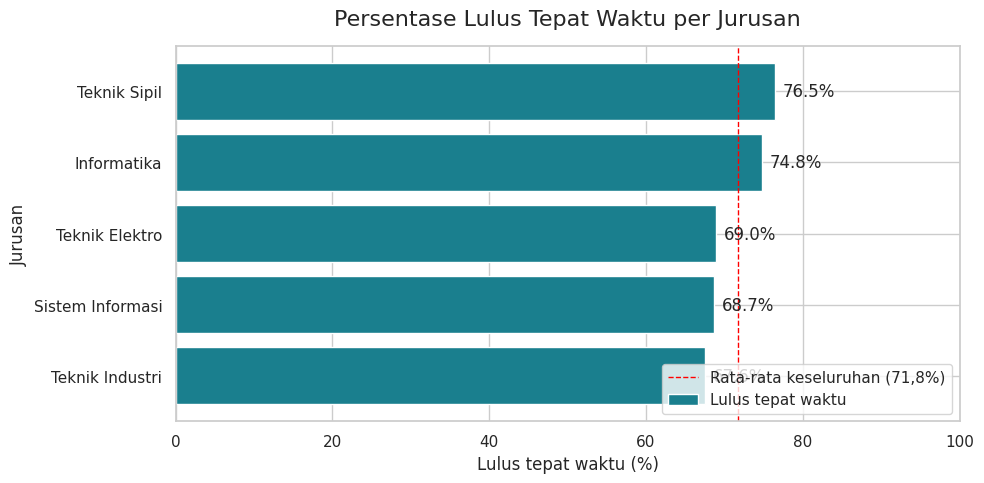

In [8]:
per_jurusan = (df.groupby("jurusan")["tepat_waktu"].mean() * 100).sort_values()

plt.figure(figsize=(10, 5))
bars = plt.barh(per_jurusan.index, per_jurusan.values, color="#1A7F8E", label="Lulus tepat waktu")
plt.title("Persentase Lulus Tepat Waktu per Jurusan", fontsize=16, pad=15)
plt.xlabel("Lulus tepat waktu (%)", fontsize=12)
plt.ylabel("Jurusan", fontsize=12)
plt.xlim(0, 100)
for b in bars:
    plt.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, "%.1f%%" % b.get_width(), va="center")
plt.axvline(df["tepat_waktu"].mean() * 100, color="red", linestyle="--", linewidth=1, label="Rata-rata keseluruhan (71,8%)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("hasil_visualisasi/05_bar_jurusan.png", dpi=150)
plt.show()

**Interpretasi:** Teknik Sipil (76,5%) dan Informatika (74,8%) berada di atas rata-rata keseluruhan, sedangkan Teknik Industri (67,6%) paling rendah. Selisih antar jurusan sekitar 9 poin persentase, relatif kecil dibanding perbedaan yang terlihat pada IPK dan kehadiran.

## 9. Bar Chart: Aktivitas di Luar Kuliah

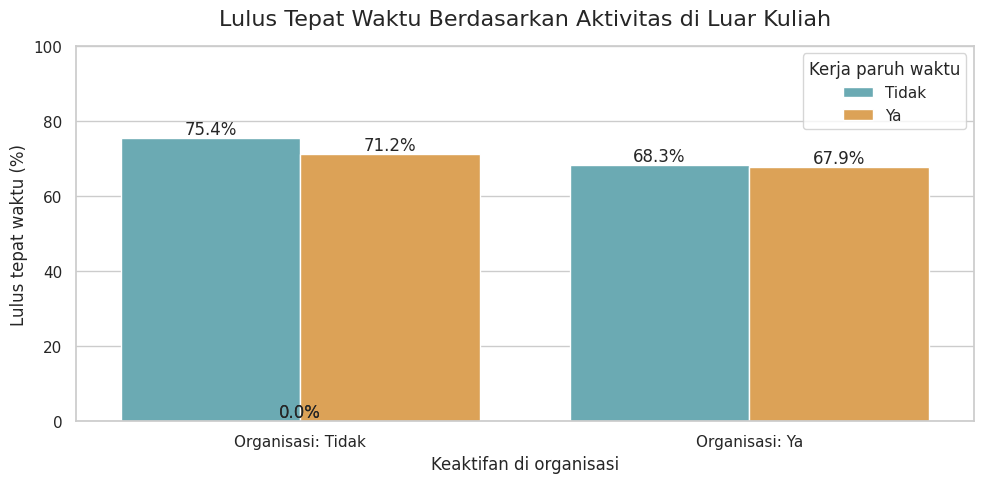

In [9]:
akt = df.groupby(["aktif_organisasi", "kerja_paruh_waktu"])["tepat_waktu"].mean().mul(100).reset_index()
akt["kelompok"] = "Organisasi: " + akt["aktif_organisasi"]

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=akt, x="kelompok", y="tepat_waktu", hue="kerja_paruh_waktu",
                 palette=["#5FB3BF", "#F2A541"], hue_order=["Tidak", "Ya"])
plt.title("Lulus Tepat Waktu Berdasarkan Aktivitas di Luar Kuliah", fontsize=16, pad=15)
plt.xlabel("Keaktifan di organisasi", fontsize=12)
plt.ylabel("Lulus tepat waktu (%)", fontsize=12)
plt.ylim(0, 100)
for p in ax.patches:
    ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 1, "%.1f%%" % p.get_height(), ha="center")
plt.legend(title="Kerja paruh waktu")
plt.tight_layout()
plt.savefig("hasil_visualisasi/06_bar_aktivitas_luar_kuliah.png", dpi=150)
plt.show()

**Interpretasi:** Mahasiswa yang tidak ikut organisasi dan tidak bekerja paruh waktu memiliki persentase tepat waktu tertinggi (75,4%), sedangkan yang aktif di organisasi berada di kisaran 68%. Pengaruh aktivitas di luar kuliah ada tetapi kecil (sekitar 3 sampai 7 poin persentase), dan kelompok yang bekerja paruh waktu serta aktif organisasi jumlahnya sedikit (56 mahasiswa), jadi angkanya perlu dibaca hati-hati.

## 10. Heatmap: Korelasi Antarvariabel Numerik

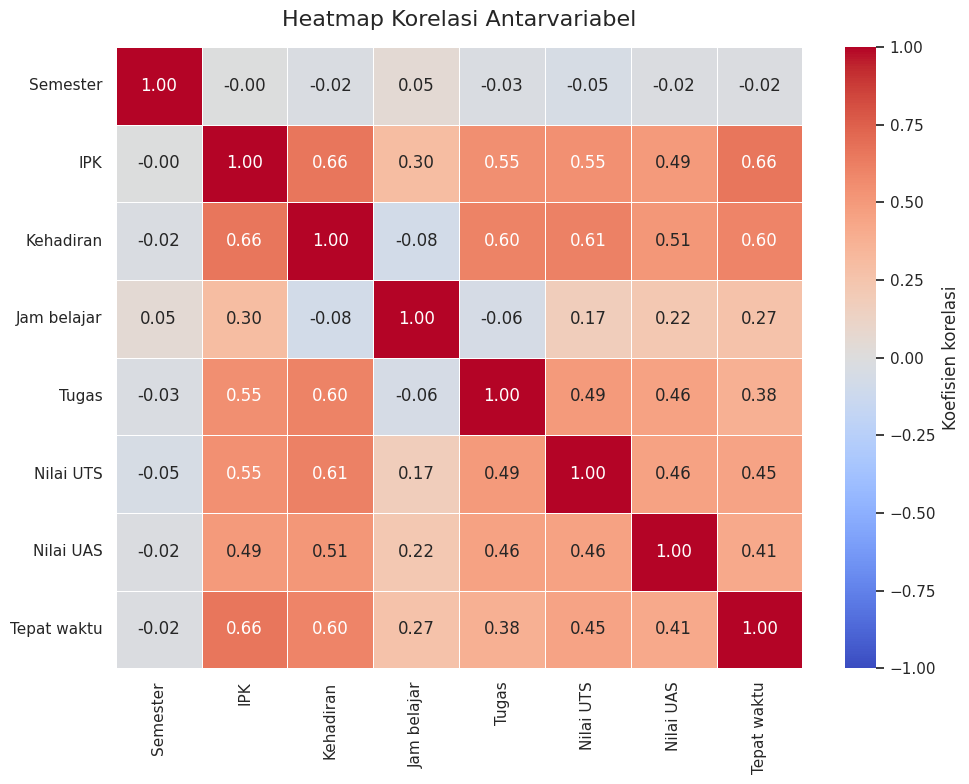

In [10]:
kolom_num = ["semester", "ipk", "kehadiran_persen", "jam_belajar_per_minggu",
             "tugas_terkumpul", "nilai_uts", "nilai_uas", "tepat_waktu"]
label = ["Semester", "IPK", "Kehadiran", "Jam belajar", "Tugas", "Nilai UTS", "Nilai UAS", "Tepat waktu"]
korelasi = df[kolom_num].corr()
korelasi.index = label
korelasi.columns = label

plt.figure(figsize=(10, 8))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Koefisien korelasi"})
plt.title("Heatmap Korelasi Antarvariabel", fontsize=16, pad=15)
plt.tight_layout()
plt.savefig("hasil_visualisasi/07_heatmap_korelasi.png", dpi=150)
plt.show()

**Interpretasi:** Variabel yang paling berkorelasi dengan kelulusan tepat waktu adalah **IPK (0,66)** dan **kehadiran (0,60)**, diikuti nilai UTS (0,45), nilai UAS (0,41), tugas terkumpul (0,38), dan jam belajar (0,27). Semester hampir tidak berkorelasi (-0,02). Kehadiran juga berkorelasi kuat dengan IPK (0,66), nilai UTS (0,61), dan tugas (0,60), sehingga kehadiran tampak berkaitan dengan capaian akademik secara umum. Korelasi menunjukkan keterkaitan, bukan sebab-akibat.

## 11. Ringkasan Visualisasi (untuk Publikasi)
Empat visualisasi utama digabung dalam satu gambar ringkasan.

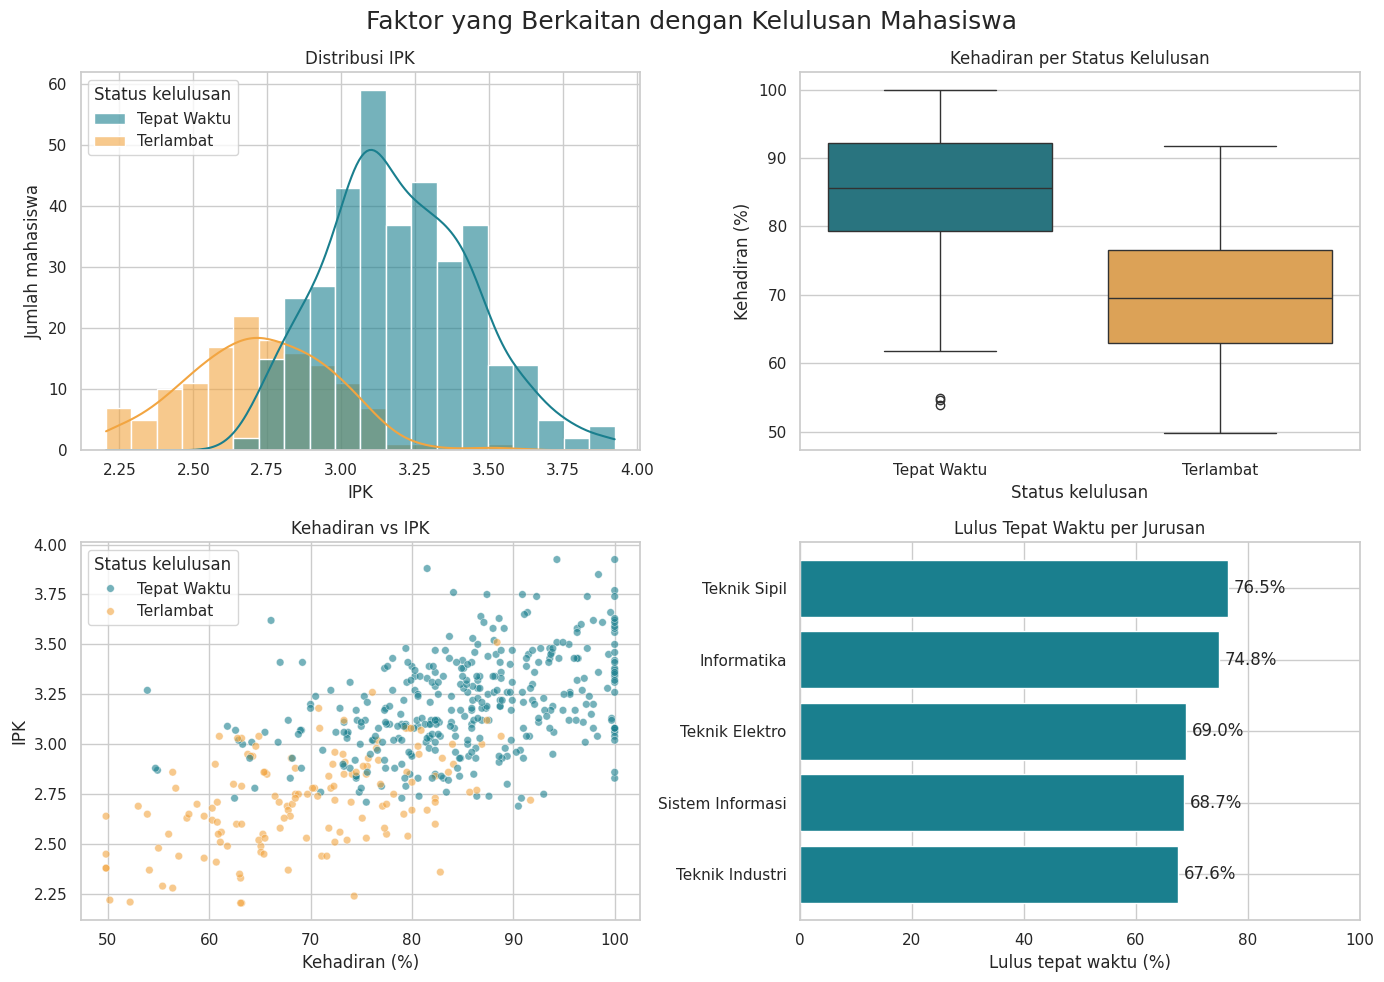

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(data=df, x="ipk", hue="status_kelulusan", bins=20, kde=True, palette=WARNA,
             hue_order=["Tepat Waktu", "Terlambat"], alpha=0.6, ax=axes[0, 0])
axes[0, 0].set_title("Distribusi IPK")
axes[0, 0].set_xlabel("IPK")
axes[0, 0].set_ylabel("Jumlah mahasiswa")
sns.move_legend(axes[0, 0], "upper left", title="Status kelulusan")

sns.boxplot(data=df, x="status_kelulusan", y="kehadiran_persen", hue="status_kelulusan",
            order=["Tepat Waktu", "Terlambat"], palette=WARNA, legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Kehadiran per Status Kelulusan")
axes[0, 1].set_xlabel("Status kelulusan")
axes[0, 1].set_ylabel("Kehadiran (%)")

sns.scatterplot(data=df, x="kehadiran_persen", y="ipk", hue="status_kelulusan", palette=WARNA,
                hue_order=["Tepat Waktu", "Terlambat"], alpha=0.6, s=30, ax=axes[1, 0])
axes[1, 0].set_title("Kehadiran vs IPK")
axes[1, 0].set_xlabel("Kehadiran (%)")
axes[1, 0].set_ylabel("IPK")
sns.move_legend(axes[1, 0], "upper left", title="Status kelulusan")

axes[1, 1].barh(per_jurusan.index, per_jurusan.values, color="#1A7F8E")
axes[1, 1].set_title("Lulus Tepat Waktu per Jurusan")
axes[1, 1].set_xlabel("Lulus tepat waktu (%)")
axes[1, 1].set_xlim(0, 100)
for i, v in enumerate(per_jurusan.values):
    axes[1, 1].text(v + 1, i, "%.1f%%" % v, va="center")

plt.suptitle("Faktor yang Berkaitan dengan Kelulusan Mahasiswa", fontsize=18)
plt.tight_layout()
plt.savefig("hasil_visualisasi/08_ringkasan_dashboard.png", dpi=150)
plt.show()

## 12. Kesimpulan
1. **IPK dan kehadiran** adalah dua variabel yang paling terkait dengan kelulusan tepat waktu (korelasi 0,66 dan 0,60). Mahasiswa tepat waktu punya median IPK 3,17 dan kehadiran 85,6%, sedangkan mahasiswa terlambat 2,72 dan 69,6%.
2. **Jam belajar, nilai UTS/UAS, dan tugas** juga berkaitan positif dengan kelulusan, tetapi lebih lemah (korelasi 0,27 sampai 0,45).
3. **Semester dan jurusan** tidak banyak membedakan kelulusan: IPK dan persentase tepat waktu stabil antar semester, dan selisih antar jurusan sekitar 9 poin persentase.
4. **Aktivitas di luar kuliah** (organisasi dan kerja paruh waktu) berkaitan dengan persentase tepat waktu yang sedikit lebih rendah, namun selisihnya kecil.
5. Hasil ini menunjukkan keterkaitan antarvariabel, bukan hubungan sebab-akibat. Untuk prediksi kelulusan, IPK, kehadiran, dan nilai ujian layak dijadikan fitur utama pada tahap pemodelan berikutnya.

## 13. Simpan Hasil Visualisasi

In [12]:
import shutil
shutil.make_archive("hasil_visualisasi", "zip", "hasil_visualisasi")
try:
    from google.colab import files
    files.download("hasil_visualisasi.zip")
except ImportError:
    pass